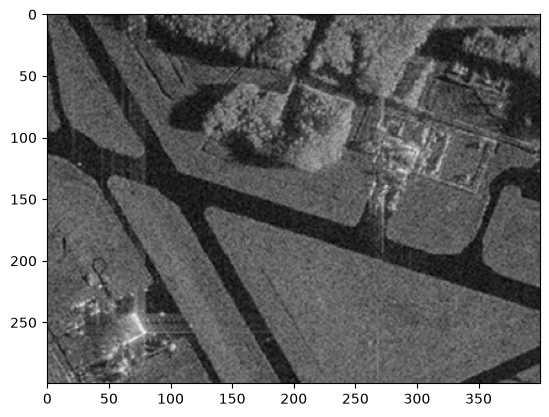

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy
from skimage.metrics import structural_similarity, mean_squared_error

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray,cmap = "gray")
plt.show()

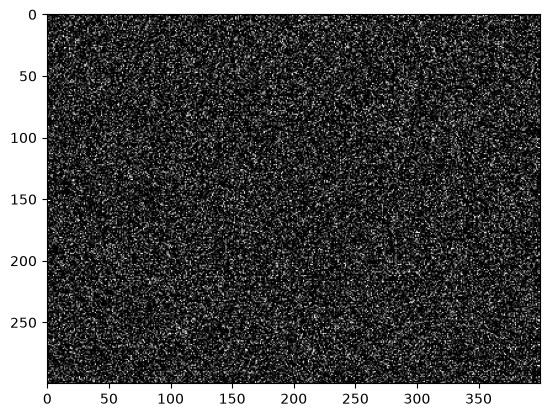

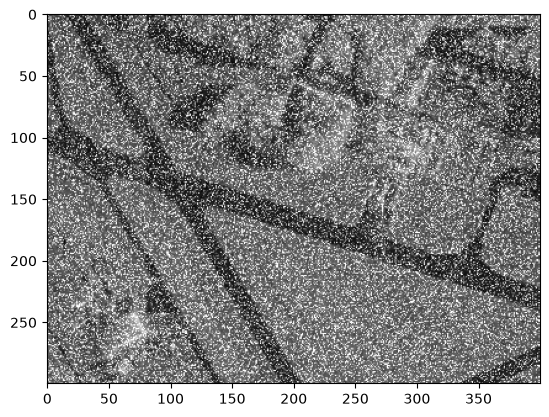

In [2]:
mean = 0
stddev = 100
noize_gauss =  np.zeros(image_gray.shape,np.uint8)
cv2.randn(noize_gauss, mean,stddev)
plt.imshow(noize_gauss, cmap ="gray")
plt.show()

image_ng = cv2.add(image_gray, noize_gauss)
plt.imshow(image_ng,cmap ="gray")
plt.show()

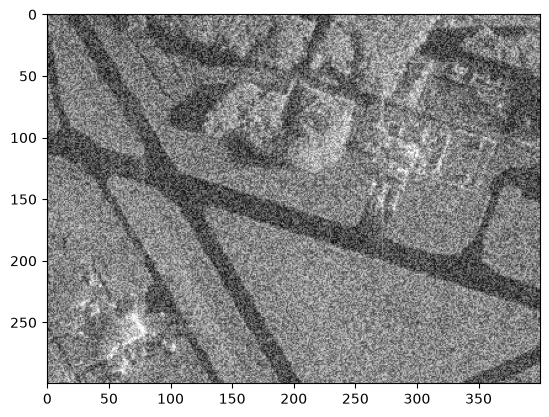

In [3]:
noise_uniform = np.random.randint(0, 100, size=image_gray.shape, dtype=np.uint8)
image_nu = cv2.add(image_gray, noise_uniform)

plt.imshow(image_nu, cmap="gray")
plt.show()

uniform + Median k = 3: MSE =  2712.1643083333333  SSIM =  0.43790913925187025


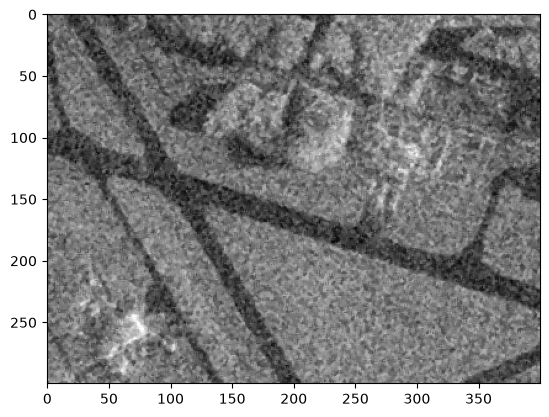

In [4]:
image_nu_m = cv2.medianBlur(image_nu,3)
mse_nu_m = mean_squared_error(image_gray,image_nu_m)
(ssim_nu_m, diff) = structural_similarity(image_gray,image_nu_m,full = True)
print("uniform + Median k = 3: MSE = ",mse_nu_m," SSIM = ", ssim_nu_m)
plt.imshow(image_nu_m, cmap="gray")
plt.show()

Uniform + Gausse k = 3: MSE =  2563.5098416666665  SSIM =  0.6109292229777785


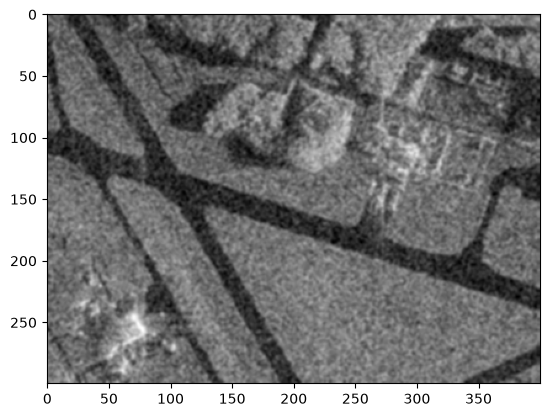

In [5]:
image_nu_g = cv2.GaussianBlur(image_nu, (5,5), 0)
mse_nu_g = mean_squared_error(image_gray, image_nu_g)
(ssim_nu_g, diff) = structural_similarity(image_gray,image_nu_g,full = True)
print("Uniform + Gausse k = 3: MSE = ",mse_nu_g," SSIM = ", ssim_nu_g)
plt.imshow(image_nu_g, cmap="gray")
plt.show()

Uniform + Bilateral:  MSE = 2580.9065083333335  SSIM = 0.538110629051729


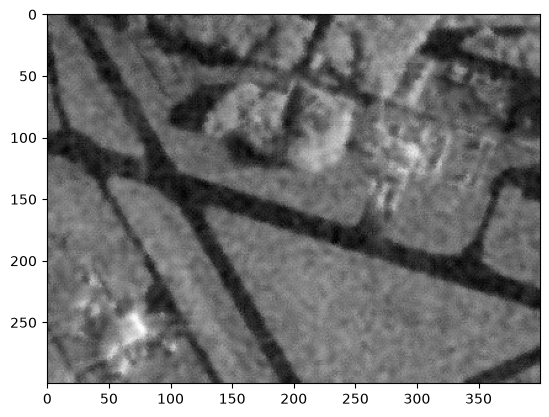

In [6]:
image_nu_b = cv2.bilateralFilter(image_nu, 9, 75, 75)
mse_nu_b = mean_squared_error(image_gray, image_nu_b)
(ssim_nu_b, diff) = structural_similarity(image_gray, image_nu_b, full=True)
print("Uniform + Bilateral:  MSE =", mse_nu_b, " SSIM =", ssim_nu_b)
plt.imshow(image_nu_b, cmap="gray")
plt.show()

Uniform + NLM h = 20:  MSE = 2611.6223416666667  SSIM = 0.5248832412399205


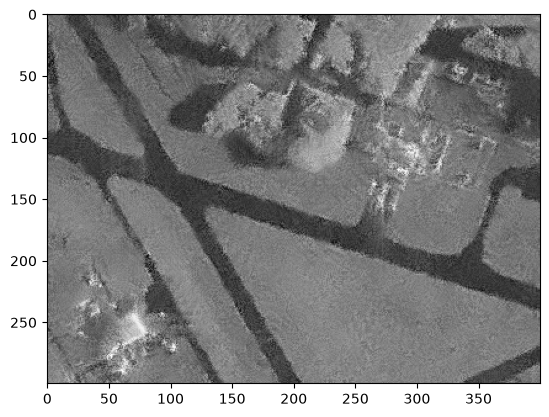

In [7]:
image_nu_nlm = cv2.fastNlMeansDenoising(image_nu, h=20)
mse_nu_nlm = mean_squared_error(image_gray, image_nu_nlm)
(ssim_nu_nlm, diff) = structural_similarity(image_gray, image_nu_nlm, full=True)
print("Uniform + NLM h = 20:  MSE =", mse_nu_nlm, " SSIM =", ssim_nu_nlm)
plt.imshow(image_nu_nlm, cmap="gray")
plt.show()

Uniform + NLM h = 100:  MSE = 2684.9534416666665  SSIM = 0.3775745401648279


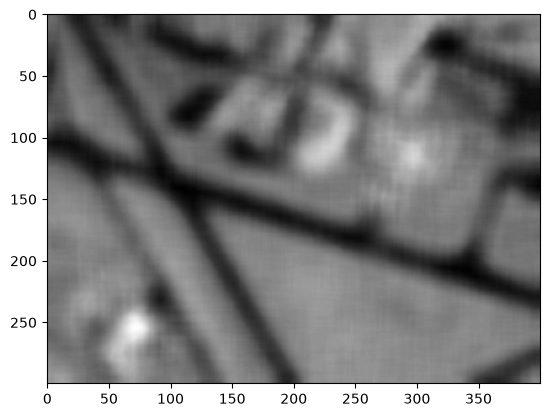

In [8]:
image_nu_nlm = cv2.fastNlMeansDenoising(image_nu, h=100)
mse_nu_nlm = mean_squared_error(image_gray, image_nu_nlm)
(ssim_nu_nlm, diff) = structural_similarity(image_gray, image_nu_nlm, full=True)
print("Uniform + NLM h = 100:  MSE =", mse_nu_nlm, " SSIM =", ssim_nu_nlm)
plt.imshow(image_nu_nlm, cmap="gray")
plt.show()

Uniform + NLM h = 30:  MSE = 2580.8711333333335  SSIM = 0.5085892628829995


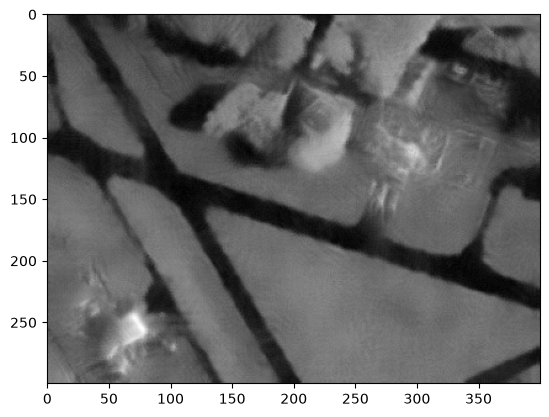

In [9]:
image_nu_nlm = cv2.fastNlMeansDenoising(image_nu, h=30)
mse_nu_nlm = mean_squared_error(image_gray, image_nu_nlm)
(ssim_nu_nlm, diff) = structural_similarity(image_gray, image_nu_nlm, full=True)
print("Uniform + NLM h = 30:  MSE =", mse_nu_nlm, " SSIM =", ssim_nu_nlm)
plt.imshow(image_nu_nlm, cmap="gray")
plt.show()

In [21]:
print("Для равномерного шума лучше NLM с параметром h = 20, шум почти полностью убрался")
print("Gaussian лучше по SSIM, но он меньше убрал шум")

Для равномерного шума лучше NLM с параметром h = 20, шум почти полностью убрался
Gaussian лучше по SSIM, но он меньше убрал шум


Gauss + Median k=3: MSE =  933.628875  SSIM =  0.35698254553132164


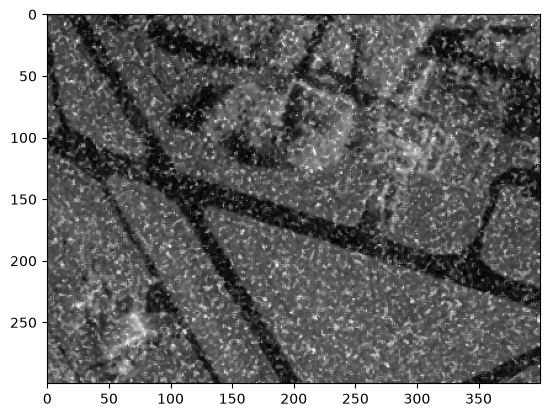

In [11]:
image_ng_m = cv2.medianBlur(image_ng,3)
mse_ng_m = mean_squared_error(image_gray,image_ng_m)
(ssim_ng_m, diff) = structural_similarity(image_gray,image_ng_m, full = True)
print("Gauss + Median k=3: MSE = ", mse_ng_m, " SSIM = ", ssim_ng_m)
plt.imshow(image_ng_m, cmap="gray")
plt.show()

Gauss + GAuss: MSE =  1654.4587166666668  SSIM =  0.45632378287207437


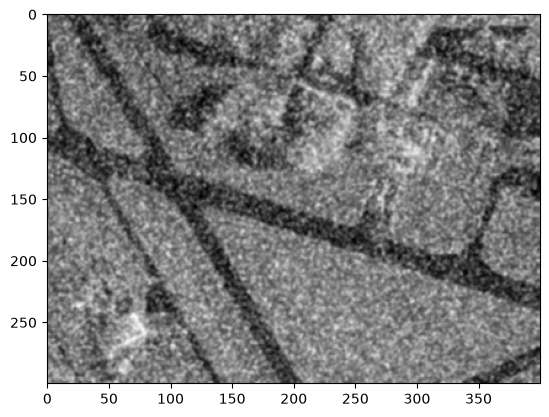

In [12]:
image_ng_g = cv2.GaussianBlur(image_ng, (5,5), 0)
mse_ng_g = mean_squared_error(image_gray, image_ng_g)
(ssim_ng_g, diff) = structural_similarity(image_gray,image_ng_g,full = True)
print("Gauss + GAuss: MSE = ",mse_ng_g," SSIM = ", ssim_ng_g)
plt.imshow(image_ng_g, cmap="gray")
plt.show()

Gausse + Bilateral:  MSE = 1661.1478333333334  SSIM = 0.25809713660900596


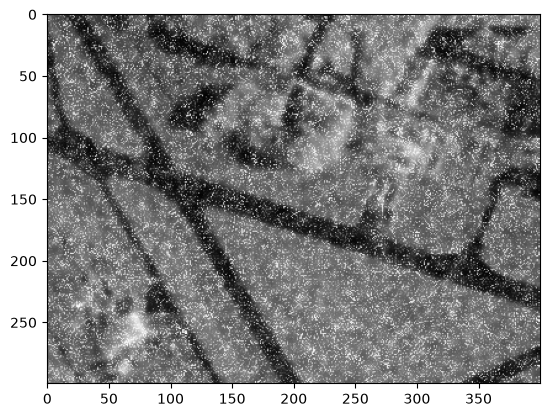

In [13]:
image_ng_b = cv2.bilateralFilter(image_ng, 9, 75, 75)
mse_ng_b = mean_squared_error(image_gray, image_ng_b)
(ssim_ng_b, diff) = structural_similarity(image_gray, image_ng_b, full=True)
print("Gausse + Bilateral:  MSE =", mse_ng_b, " SSIM =", ssim_ng_b)
plt.imshow(image_ng_b, cmap="gray")
plt.show()

Gausse + Bilateral:  MSE = 1412.605825  SSIM = 0.42235531560826733


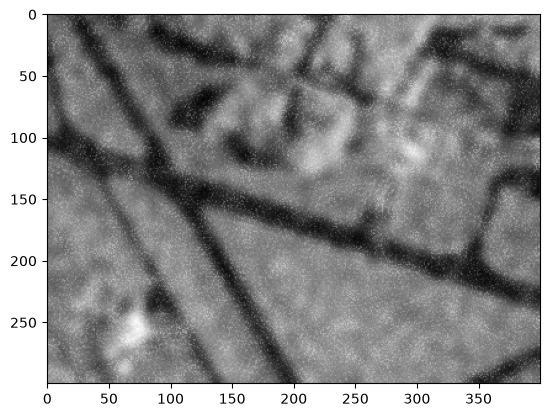

In [14]:
image_ng_b = cv2.bilateralFilter(image_ng, 15, 150, 150)
mse_ng_b = mean_squared_error(image_gray, image_ng_b)
(ssim_ng_b, diff) = structural_similarity(image_gray, image_ng_b, full=True)
print("Gausse + Bilateral:  MSE =", mse_ng_b, " SSIM =", ssim_ng_b)
plt.imshow(image_ng_b, cmap="gray")
plt.show()

Gauss + NLM h = 20:  MSE = 4053.5947166666665  SSIM = 0.11974857389103548


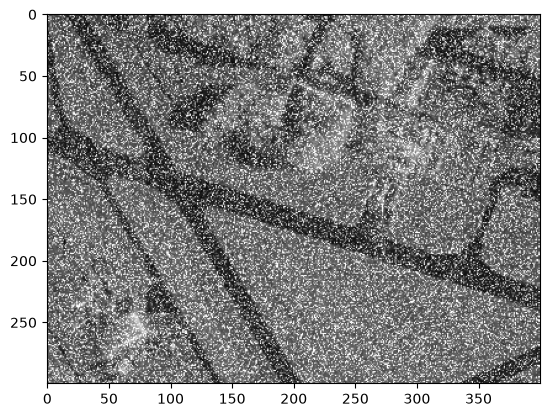

In [15]:
image_ng_nlm = cv2.fastNlMeansDenoising(image_ng, h=20)
mse_ng_nlm = mean_squared_error(image_gray, image_ng_nlm)
(ssim_ng_nlm, diff) = structural_similarity(image_gray, image_ng_nlm, full=True)
print("Gauss + NLM h = 20:  MSE =", mse_ng_nlm, " SSIM =", ssim_ng_nlm)
plt.imshow(image_ng_nlm, cmap="gray")
plt.show()

Gauss + NLM h = 100:  MSE = 1635.4709583333333  SSIM = 0.392934151568681


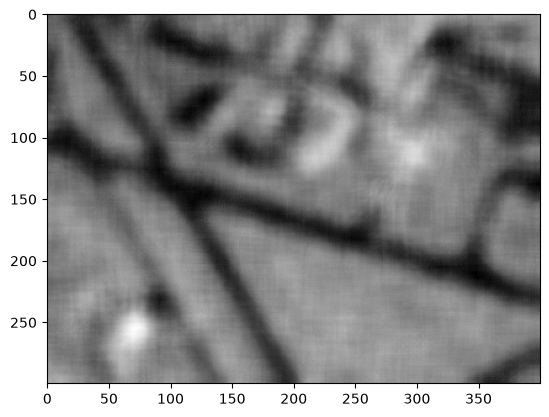

In [16]:
image_ng_nlm = cv2.fastNlMeansDenoising(image_ng, h=100)
mse_ng_nlm = mean_squared_error(image_gray, image_ng_nlm)
(ssim_ng_nlm, diff) = structural_similarity(image_gray, image_ng_nlm, full=True)
print("Gauss + NLM h = 100:  MSE =", mse_ng_nlm, " SSIM =", ssim_ng_nlm)
plt.imshow(image_ng_nlm, cmap="gray")
plt.show()

Gauss + NLM h = 30:  MSE = 2369.7148  SSIM = 0.22152329861439612


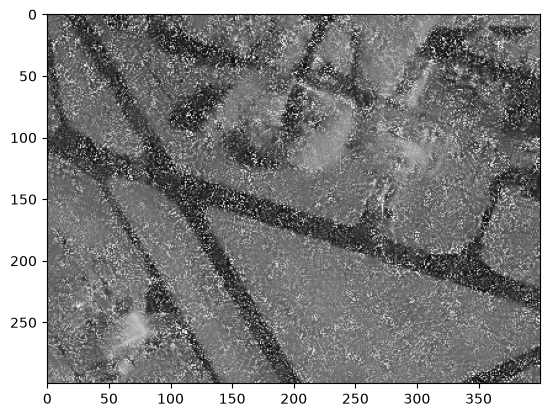

In [17]:
image_ng_nlm = cv2.fastNlMeansDenoising(image_ng, h=30)
mse_ng_nlm = mean_squared_error(image_gray, image_ng_nlm)
(ssim_ng_nlm, diff) = structural_similarity(image_gray, image_ng_nlm, full=True)
print("Gauss + NLM h = 30:  MSE =", mse_ng_nlm, " SSIM =", ssim_ng_nlm)
plt.imshow(image_ng_nlm, cmap="gray")
plt.show()

In [22]:
print("Для шума Гаусса лучший SSIM у Gaussian, но визуально так же много шума, у Bilateral (15,150,150) SSIM = 0.422")
print("NLM h=100 даёт SSIM = 0.392 чуть хуже, но сильнее убирает шум")
print("Bilateral сохраняет структуру лучше, NLM сильнее сглаживает")

Для шума Гаусса лучший SSIM у Gaussian, но визуально так же много шума, у Bilateral (15,150,150) SSIM = 0.422
NLM h=100 даёт SSIM = 0.392 чуть хуже, но сильнее убирает шум
Bilateral сохраняет структуру лучше, NLM сильнее сглаживает
